# SpendWise - Personal Expense Analyzer
K Thanayan Reddy (2025BCS0174), Pratik Raj (2025BCS0281) - IIIT Kottayam

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import spendwise as sw

pd.set_option('display.width', 120)

## 1. Import expenses from CSV
Some rows have a blank category.

In [2]:
df = sw.load_csv('data/expenses.csv')
print(df.shape)
print('Blank categories:', (df['category'] == '').sum())
df.head()

(294, 5)
Blank categories: 121


,date,description,category,amount,month
0,2026-01-01,Mobile recharge Jio,Bills,283,2026-01
1,2026-01-02,Room rent,,6000,2026-01
2,2026-01-02,Stationery shop,Shopping,45,2026-01
3,2026-01-03,Swiggy Instamart groceries,,489,2026-01
4,2026-01-04,Tea and snacks,Food,60,2026-01


## 2. Auto-categorize
Blank categories are filled using keyword rules from `spendwise.py`.

In [3]:
df, filled = sw.fill_categories(df)
print('Filled by rules:', filled)
df['category'].value_counts()

Filled by rules: 121


category
Food             138
Transport         44
Entertainment     26
Others            25
Shopping          24
Bills             17
Health            14
Rent               6
Name: count, dtype: int64

## 3. Total and category-wise expenses

In [4]:
total = df['amount'].sum()
print('Total spend: Rs', total)
cat_total = df.groupby('category')['amount'].sum().sort_values(ascending=False)
cat_total

Total spend: Rs 123656


category
Food             38201
Rent             36000
Shopping         13480
Health            8161
Bills             7517
Transport         7210
Entertainment     6596
Others            6491
Name: amount, dtype: int64

In [5]:
monthly = df.groupby('month')['amount'].sum()
monthly

month
2026-01    22057
2026-02    19599
2026-03    22041
2026-04    19969
2026-05    21618
2026-06    18372
Name: amount, dtype: int64

## 4. Charts

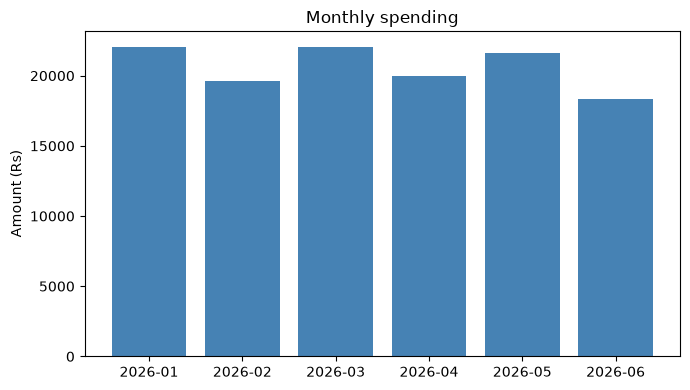

In [6]:
plt.figure(figsize=(7, 4))
plt.bar(monthly.index, monthly.values, color='steelblue')
plt.title('Monthly spending')
plt.ylabel('Amount (Rs)')
plt.tight_layout()
plt.savefig('charts/monthly_bar.png', dpi=120)
plt.show()

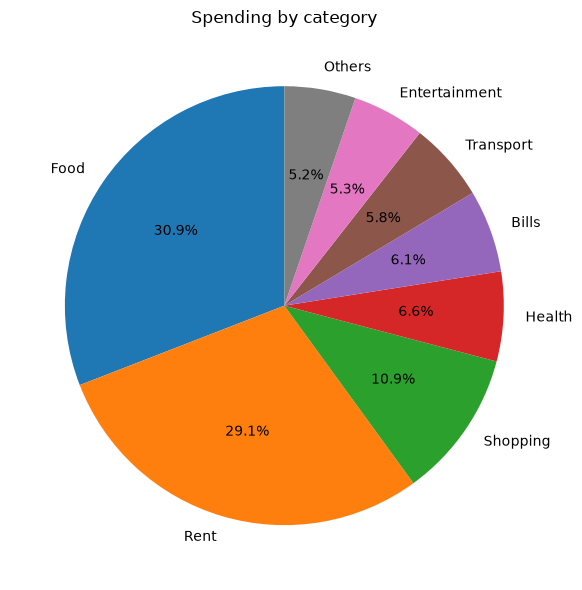

In [7]:
plt.figure(figsize=(6, 6))
plt.pie(cat_total.values, labels=cat_total.index, autopct='%1.1f%%', startangle=90)
plt.title('Spending by category')
plt.tight_layout()
plt.savefig('charts/category_pie.png', dpi=120)
plt.show()

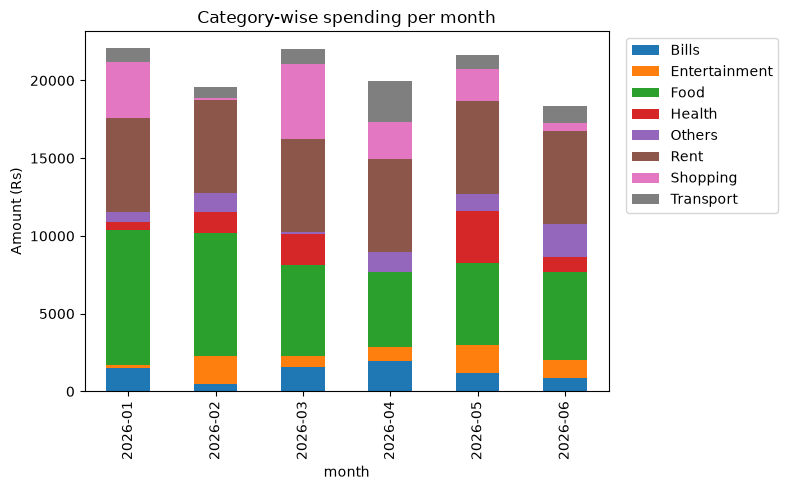

In [8]:
pivot = df.pivot_table(index='month', columns='category', values='amount', aggfunc='sum', fill_value=0)
pivot.plot(kind='bar', stacked=True, figsize=(8, 5))
plt.title('Category-wise spending per month')
plt.ylabel('Amount (Rs)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('charts/category_stacked.png', dpi=120)
plt.show()

## 5. SQLite storage and queries

In [9]:
sw.save_to_db(df, 'spendwise.db')
sw.run_query('spendwise.db', 'SELECT COUNT(*) AS rows, SUM(amount) AS total FROM transactions')

,rows,total
0,294,123656


In [10]:
sw.run_query('spendwise.db', '''SELECT category, COUNT(*) AS n, SUM(amount) AS total
FROM transactions GROUP BY category ORDER BY total DESC''')

,category,n,total
0,Food,138,38201
1,Rent,6,36000
2,Shopping,24,13480
3,Health,14,8161
4,Bills,17,7517
5,Transport,44,7210
6,Entertainment,26,6596
7,Others,25,6491


In [11]:
sw.run_query('spendwise.db', '''SELECT month, SUM(amount) AS food FROM transactions
WHERE category = 'Food' GROUP BY month''')

,month,food
0,2026-01,8705
1,2026-02,7890
2,2026-03,5897
3,2026-04,4819
4,2026-05,5262
5,2026-06,5628


## 6. Budgets and overspending
Monthly budget per category in Rs.

In [12]:
budgets = {'Food': 7000, 'Transport': 2000, 'Shopping': 3000, 'Bills': 1500,
           'Entertainment': 1500, 'Health': 1500, 'Rent': 6000, 'Others': 1500}
over = sw.check_budget(df, budgets)
print('Overspent cases:', len(over))
over

Overspent cases: 13


,month,category,amount,budget,over_by
0,2026-01,Bills,1529,1500,29
1,2026-01,Food,8705,7000,1705
2,2026-01,Shopping,3646,3000,646
3,2026-02,Entertainment,1810,1500,310
4,2026-02,Food,7890,7000,890
5,2026-03,Bills,1554,1500,54
6,2026-03,Health,1975,1500,475
7,2026-03,Shopping,4814,3000,1814
8,2026-04,Bills,1944,1500,444
9,2026-04,Transport,2614,2000,614


## 7. Statistics

In [13]:
stats = df['amount'].describe()
print('Mean:', round(df['amount'].mean(), 2))
print('Median:', df['amount'].median())
print('Std:', round(df['amount'].std(), 2))

Mean: 420.6
Median: 225.5
Std: 863.0


In [14]:
df.nlargest(5, 'amount')[['date', 'description', 'category', 'amount']]

,date,description,category,amount
1,2026-01-02,Room rent,Rent,6000
50,2026-02-02,Room rent,Rent,6000
100,2026-03-02,Room rent,Rent,6000
148,2026-04-02,Room rent,Rent,6000
196,2026-05-02,Room rent,Rent,6000


Rent fills the top 5, so here is the top 5 without rent.

In [15]:
df[df['category'] != 'Rent'].nlargest(5, 'amount')[['date', 'description', 'category', 'amount']]

,date,description,category,amount
12,2026-01-07,Myntra - shoes,Shopping,2116
224,2026-05-21,Myntra - shoes,Shopping,1908
107,2026-03-07,Myntra - shoes,Shopping,1812
268,2026-06-12,Zomato - pizza,Food,1764
163,2026-04-14,Electricity share,Bills,1512


Unusual expenses: amount above Q3 + 1.5*IQR (rent left out since it is fixed).

In [16]:
unusual, limit = sw.iqr_flags(df)
print('IQR upper limit:', limit)
print('Unusual count:', len(unusual))
unusual[['date', 'description', 'category', 'amount']]

IQR upper limit: 935.25
Unusual count: 11


,date,description,category,amount
12,2026-01-07,Myntra - shoes,Shopping,2116
59,2026-02-08,Movie ticket PVR,Entertainment,1020
71,2026-02-13,Pharmacy - medicines,Health,1096
74,2026-02-15,Zomato - pizza,Food,1256
102,2026-03-05,Amazon - earphones,Shopping,1249
107,2026-03-07,Myntra - shoes,Shopping,1812
146,2026-03-27,Swiggy order - biryani,Food,1080
163,2026-04-14,Electricity share,Bills,1512
216,2026-05-15,Hospital consultation,Health,1448
224,2026-05-21,Myntra - shoes,Shopping,1908


## 8. Summary report

In [17]:
summary = cat_total.reset_index()
summary.columns = ['category', 'total']
summary['percent'] = (summary['total'] / total * 100).round(1)
summary.to_csv('summary.csv', index=False)
over.to_csv('overspending.csv', index=False)
lines = ['SpendWise Expense Summary', f'Transactions: {len(df)}', f'Total spend: Rs {total}',
         f'Average per month: Rs {monthly.mean():.0f}', f'Top category: {cat_total.index[0]} (Rs {cat_total.iloc[0]})',
         f'Mean: {df.amount.mean():.2f}  Median: {df.amount.median()}  Std: {df.amount.std():.2f}',
         f'Unusual expenses: {len(unusual)}', f'Overspent cases: {len(over)}']
lines += [f'  {r.month} {r.category}: spent {r.amount}, budget {r.budget:.0f}, over by {r.over_by:.0f}' for r in over.itertuples()]
open('summary_report.txt', 'w').write('\n'.join(lines))
print('\n'.join(lines))

SpendWise Expense Summary
Transactions: 294
Total spend: Rs 123656
Average per month: Rs 20609
Top category: Food (Rs 38201)
Mean: 420.60  Median: 225.5  Std: 863.00
Unusual expenses: 11
Overspent cases: 13
  2026-01 Bills: spent 1529, budget 1500, over by 29
  2026-01 Food: spent 8705, budget 7000, over by 1705
  2026-01 Shopping: spent 3646, budget 3000, over by 646
  2026-02 Entertainment: spent 1810, budget 1500, over by 310
  2026-02 Food: spent 7890, budget 7000, over by 890
  2026-03 Bills: spent 1554, budget 1500, over by 54
  2026-03 Health: spent 1975, budget 1500, over by 475
  2026-03 Shopping: spent 4814, budget 3000, over by 1814
  2026-04 Bills: spent 1944, budget 1500, over by 444
  2026-04 Transport: spent 2614, budget 2000, over by 614
  2026-05 Entertainment: spent 1851, budget 1500, over by 351
  2026-05 Health: spent 3300, budget 1500, over by 1800
  2026-06 Others: spent 2120, budget 1500, over by 620
